# AquaSense+ database design: run and test

## 1. Install the Python driver (once)

In [1]:
%pip install psycopg2-binary pandas

Note: you may need to restart the kernel to use updated packages.


## 2. Connection settings
Change `PGPASSWORD` to the password you set when installing PostgreSQL. On a Mac with Homebrew, delete the PATH line and set `PGUSER` to your Mac username, leaving the password empty.

In [2]:
import os, platform

if platform.system() == "Windows":
    os.environ["PATH"] += r";C:\Program Files\PostgreSQL\16\bin"   
os.environ["PGUSER"] = "postgres"
os.environ["PGPASSWORD"] = "vincent"   
os.environ["PGHOST"] = "localhost"
os.environ["PGCLIENTENCODING"] = "UTF8"

!psql --version

psql (PostgreSQL) 16.15


## 3. Create the database
If you run this a second time it says the database already exists. That's fine.

In [3]:
!createdb aquasense

## 4. Build the schema (18 tables, constraints, view)

In [4]:
!psql -d aquasense -q -f 01_schema.sql

psql:01_schema.sql:7: NOTICE:  schema "aqua" does not exist, skipping


## 5. Load the seed data (30 s to a few minutes)
The output is saved to `evidence/seed_row_counts.txt` so the evidence comes from your own run.

In [5]:
!psql -d aquasense -f 02_seed_data.sql > evidence/seed_row_counts.txt 2>&1
print(open("evidence/seed_row_counts.txt", encoding="utf-8").read()[-700:])

SET
 setseed 
---------
 
(1 row)

INSERT 0 16
INSERT 0 4
INSERT 0 12
INSERT 0 15
SELECT 1
INSERT 0 605
SELECT 21
INSERT 0 180
INSERT 0 360
INSERT 0 905
INSERT 0 3764
INSERT 0 505787
INSERT 0 42331
INSERT 0 36239
INSERT 0 1033611
INSERT 0 3019
INSERT 0 7549
INSERT 0 11880
INSERT 0 540
INSERT 0 17822
ANALYZE
           t           |  count  
-----------------------+---------
 farm                  |     180
 culture_unit          |     905
 harvest               |    3019
 stock_batch           |    3764
 sale                  |    7549
 expense               |   17822
 mortality_log         |   42331
 feeding_log           |  505787
 water_quality_reading | 1033611
(9 rows)




## 6. Constraint tests
Expect **7 ERROR lines** (T1–T7: each business rule being enforced) and one successful insert (T8).

In [6]:
!psql -d aquasense -f 03_constraint_tests.sql > evidence/constraint_tests_output.txt 2>&1
out = open("evidence/constraint_tests_output.txt", encoding="utf-8").read()
print(out)
print("ERROR lines found:", out.count("ERROR:"))

SET
BEGIN
--- T1  CHECK: feed stock can never go negative ---
SAVEPOINT
psql:03_constraint_tests.sql:12: ERROR:  new row for relation "feed_inventory" violates check constraint "feed_inventory_qty_kg_check"
DETAIL:  Failing row contains (1, 4, -999465.61, 2026-11-08 12:42:54.667005+01).
ROLLBACK
--- T2  PARTIAL UNIQUE INDEX: only one ACTIVE batch per pond ---
SAVEPOINT
psql:03_constraint_tests.sql:18: ERROR:  duplicate key value violates unique constraint "uq_one_active_batch_per_unit"
DETAIL:  Key (unit_id)=(2) already exists.
ROLLBACK
--- T3  FOREIGN KEY: feeding log for a batch that does not exist ---
SAVEPOINT
psql:03_constraint_tests.sql:23: ERROR:  insert or update on table "feeding_log" violates foreign key constraint "feeding_log_batch_id_fkey"
DETAIL:  Key (batch_id)=(999999) is not present in table "stock_batch".
ROLLBACK
--- T4  CHECK (regex): phone must be a valid +234 number ---
SAVEPOINT
psql:03_constraint_tests.sql:28: ERROR:  new row for relation "app_user" violates che

## 7. Look at the data with pandas

In [7]:
import psycopg2, pandas as pd, warnings
warnings.filterwarnings("ignore", category=UserWarning)   # pandas prefers SQLAlchemy; psycopg2 works fine
conn = psycopg2.connect(dbname="aquasense")

pd.read_sql("""
    SELECT table_name,
           pg_size_pretty(pg_total_relation_size('aqua.' || table_name)) AS size
    FROM information_schema.tables
    WHERE table_schema = 'aqua' AND table_type = 'BASE TABLE'
    ORDER BY pg_total_relation_size('aqua.' || table_name) DESC""", conn)

,table_name,size
0,water_quality_reading,113 MB
1,feeding_log,44 MB
2,growth_sample,3760 kB
3,mortality_log,3664 kB
4,expense,1552 kB
5,feed_purchase,1016 kB
6,sale,824 kB
7,stock_batch,552 kB
8,harvest,280 kB
9,culture_unit,176 kB


In [8]:
# Survival and feed per batch, from the derived-data view (nothing stored, computed on read)
pd.read_sql("SELECT * FROM aqua.v_batch_status ORDER BY batch_id LIMIT 10", conn)

,batch_id,unit_id,species_id,stocked_on,initial_count,total_dead,total_harvested,fish_remaining,survival_pct,total_feed_kg
0,1,1,1,2024-12-17,1579,287,1270,22,81.8,2283.81
1,2,2,1,2025-01-21,1868,492,1327,49,73.7,2531.43
2,3,3,1,2025-02-25,663,106,528,29,84.0,801.88
3,4,4,1,2024-12-02,4896,1234,3489,173,74.8,5808.94
4,5,5,1,2025-01-06,1331,179,1124,28,86.6,2173.67
5,6,6,1,2025-02-21,6391,969,5230,192,84.8,8511.24
6,7,7,1,2024-11-28,8144,1267,6649,228,84.4,11941.05
7,8,8,1,2025-01-02,760,115,612,33,84.9,860.47
8,9,9,1,2025-02-06,1612,333,1227,52,79.3,1932.85
9,10,10,1,2024-11-13,1913,431,1406,76,77.5,2829.74


In [9]:
# Farms per state
pd.read_sql("""SELECT s.state_name, count(*) AS farms
               FROM aqua.farm f JOIN aqua.state s USING (state_code)
               GROUP BY 1 ORDER BY 2 DESC""", conn)

,state_name,farms
0,Lagos,27
1,Oyo,17
2,Delta,17
3,Ogun,16
4,FCT Abuja,9
5,Akwa Ibom,9
6,Ondo,9
7,Niger,9
8,Kwara,9
9,Anambra,9


## 8. The ER diagram

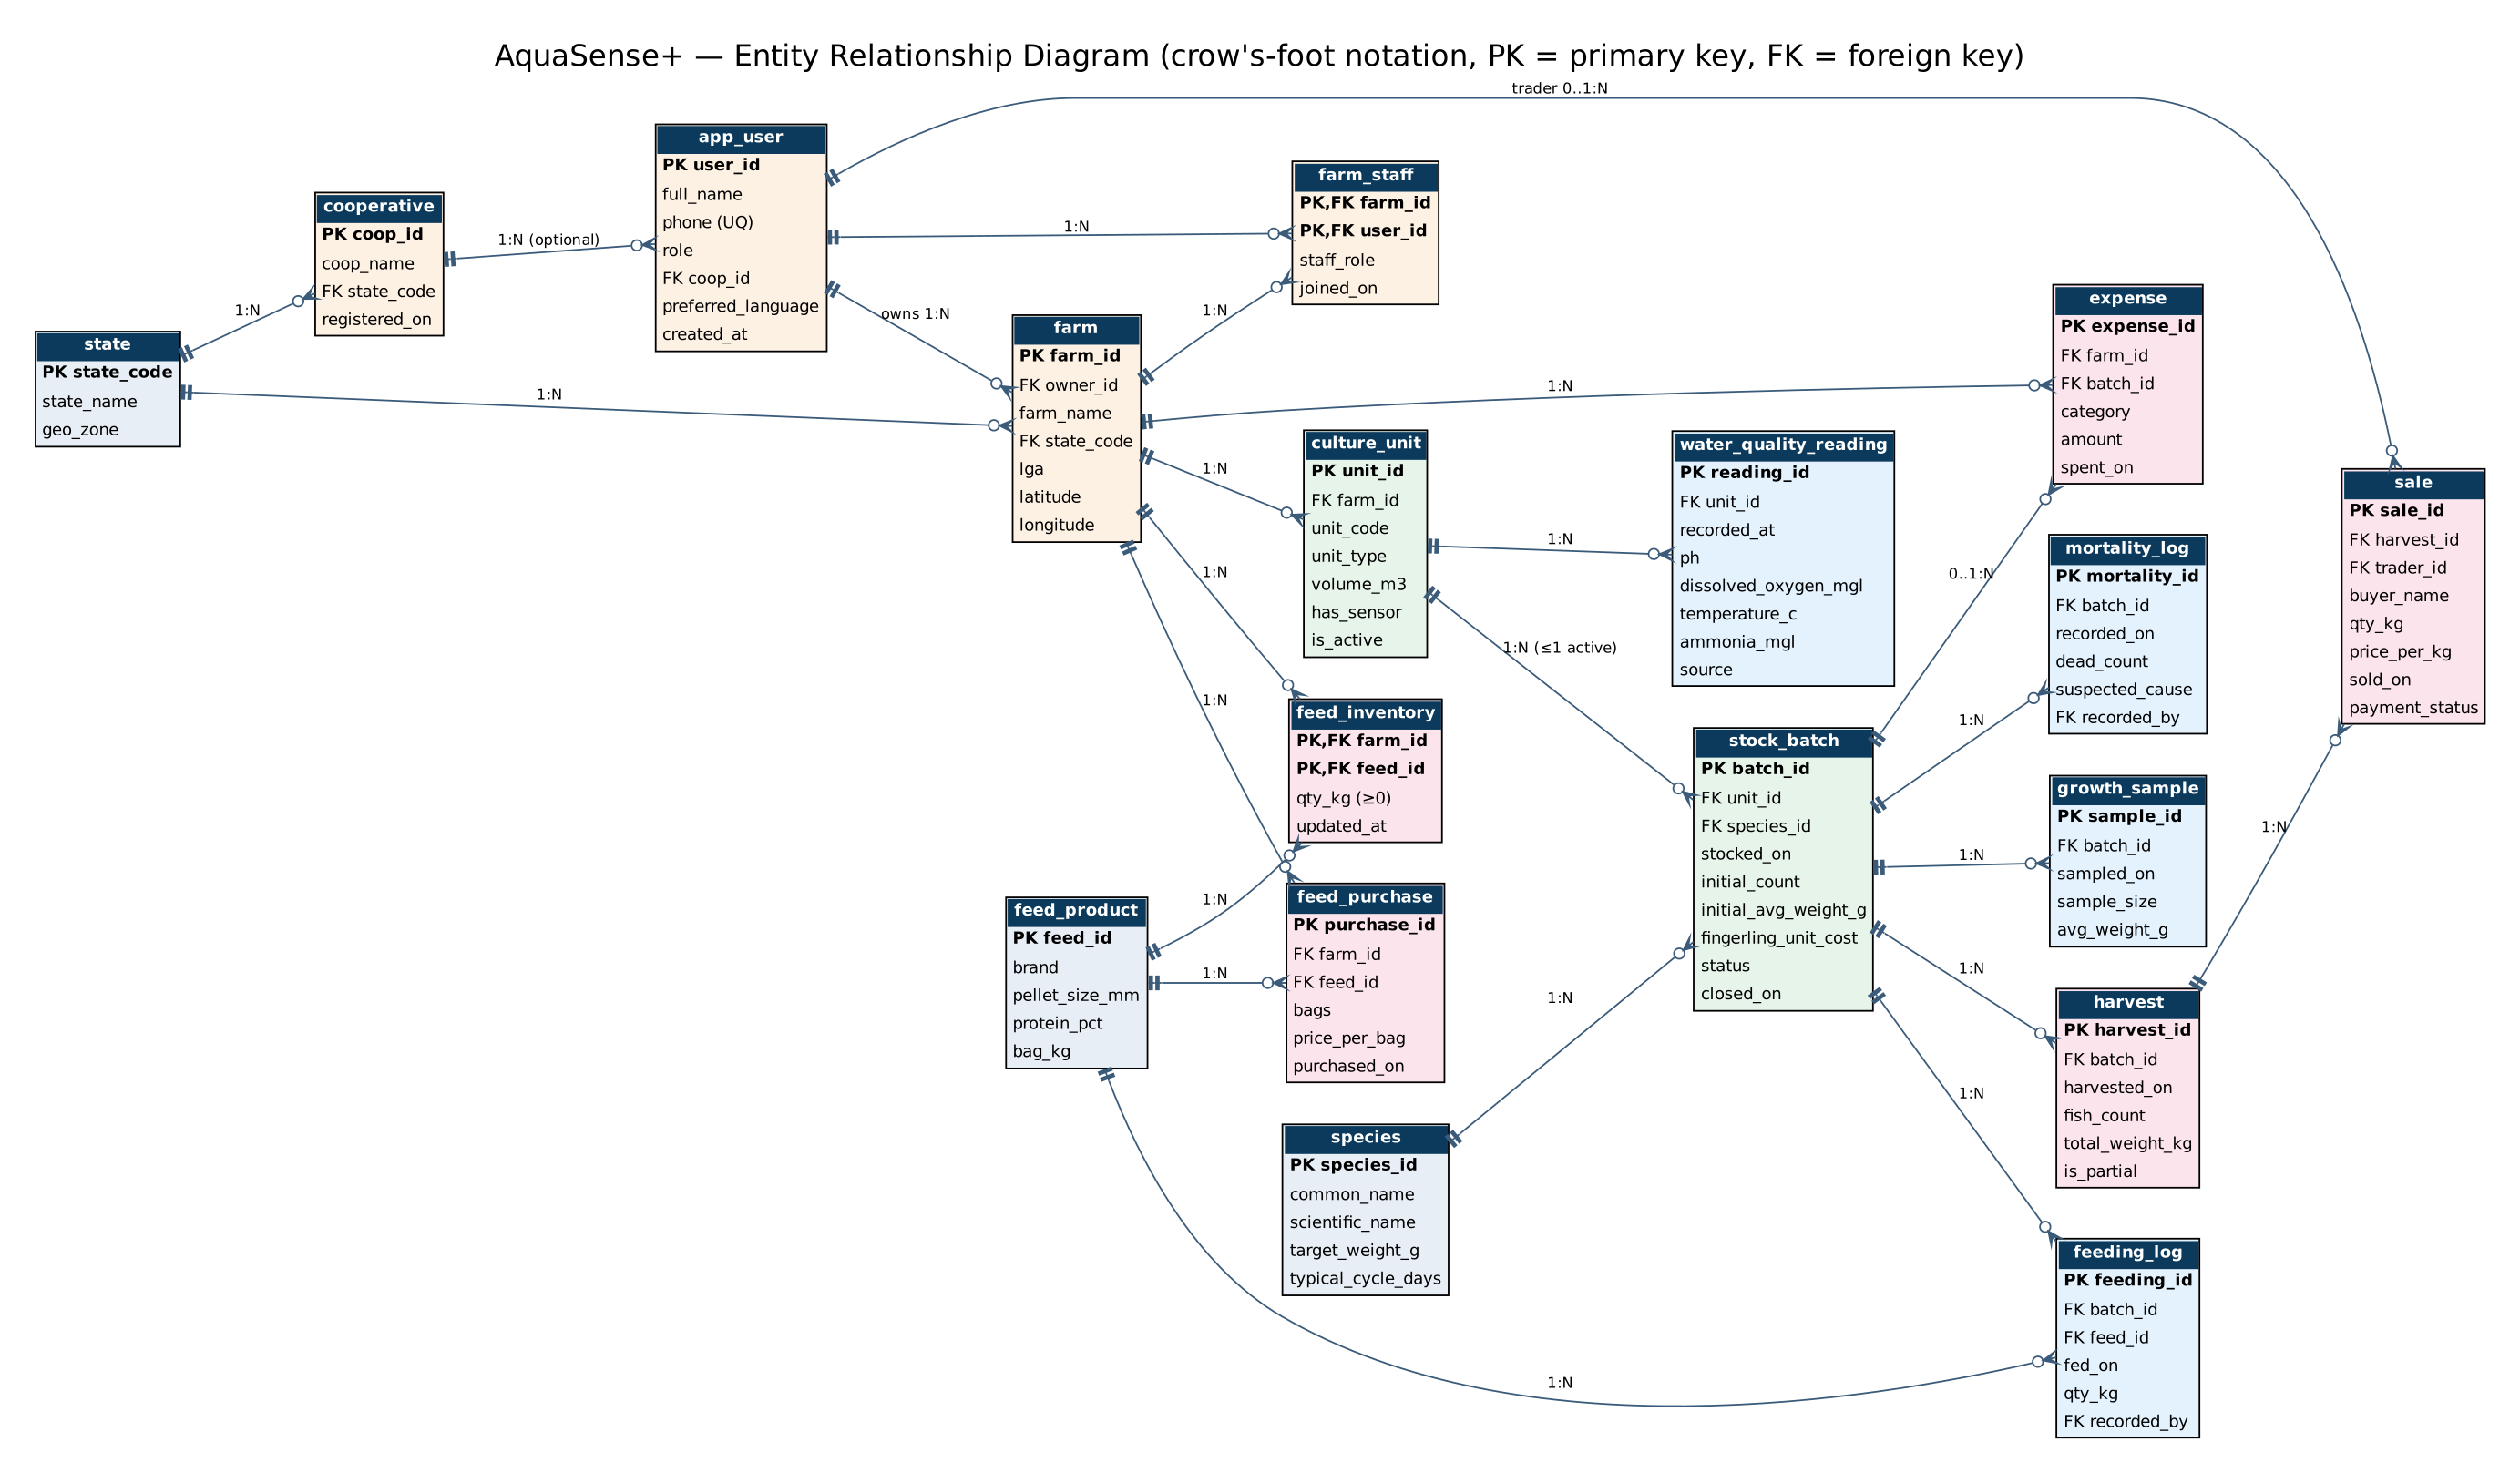

In [10]:
from IPython.display import Image
Image("erd.png")